# DRAG on a Gaussian pi pulse

DRAG is applied after a control dictionary exists. This notebook compares orders 0, 1, and 2 on a resonant Gaussian $\pi$ pulse and records leakage of a three-level transmon. The curve classes are not involved.

`tg_alpha` is $T_g \alpha$ in the same normalized units as `omega`. It is negative for a transmon. Order 1 applies the derivative quadrature, scaled by `beta`, and the analytic AC Stark detuning. Order 2 adds the higher-order Motzoi corrections. `estimate_leakage` is the bare spectral weight, not the simulated leakage.

DRAG order comparison



DRAG order 0:	100.00%

DRAG order 1:	 0.00 %

DRAG order 1:	100.00%

DRAG order 2:	 0.00 %

DRAG order 2:	100.00%


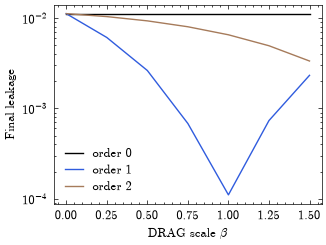

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import qutip

import qurveros.plot_configs
from qurveros import drag, plottools
from qurveros.qubit_bench import noise_experiments

pulse = drag.gaussian_pi_control(n_points=300, sigma=0.12)
tg_alpha = -20.0
betas = np.linspace(0.0, 1.5, 7)

scan = noise_experiments.drag_order_experiment(
    pulse,
    qutip.sigmax(),
    tg_alpha,
    orders=(0, 1, 2),
    betas=betas,
)

plottools.plot_drag_scan(scan)
plt.show()

In [2]:
beta_one = int(np.argmin(np.abs(scan['betas'] - 1.0)))

for index, order in enumerate(scan['orders']):
    print(
        f"order {int(order)} at beta={scan['betas'][beta_one]:.2f}: "
        f"leakage {scan['leakage'][index, beta_one]:.3e}, "
        f"peak {scan['peak_leakage'][index, beta_one]:.3e}, "
        f"subspace infidelity {scan['subspace_infidelity'][index, beta_one]:.3e}, "
        f"estimate {scan['leakage_estimate'][index, beta_one]:.3e}"
    )

order 0 at beta=1.00: leakage 1.123e-02, peak 8.584e-02, subspace infidelity 4.205e-02, estimate 1.556e-02
order 1 at beta=1.00: leakage 1.103e-04, peak 5.476e-02, subspace infidelity 3.677e-02, estimate 4.643e-09
order 2 at beta=1.00: leakage 6.548e-03, peak 8.002e-02, subspace infidelity 8.529e-03, estimate 9.671e-04
